# Studi Kasus Klasifikasi: Prediksi Nasabah yang Akan Berlangganan Deposito Berjangka

Tugas Mata Kuliah: Data Mining  
Nama: Zahrul Riskya Rahmandira
NIM: 2404010006
Program Studi: Statistika Terapan dan Komputasi


**Ringkasan.** Notebook ini menerapkan *Machine Learning* untuk masalah klasifikasi biner di dunia perbankan: memprediksi apakah seorang nasabah akan **berlangganan deposito berjangka** setelah dihubungi lewat telepon dalam kampanye *direct marketing*. Dataset yang dipakai adalah **Bank Marketing** (UCI Machine Learning Repository) dengan 45.211 data nasabah sebuah bank di Portugal.

## 1. Permasalahan yang Dihadapi

**Latar belakang.** Bank menjual produk seperti deposito berjangka lewat *telemarketing*: petugas menelepon nasabah satu per satu. Cara ini mahal dan banyak yang tidak membuahkan hasil. Pada dataset ini hanya sekitar **11,7%** nasabah yang akhirnya berlangganan, jadi sekitar 9 dari 10 panggilan tidak menghasilkan penjualan. Panggilan yang tidak perlu juga mengganggu nasabah.

**Rumusan masalah.** Bisakah bank memprediksi, *sebelum menelepon*, nasabah mana yang berpeluang besar berlangganan, sehingga tim pemasaran bisa memprioritaskan nasabah tersebut?

**Jenis masalah.** Klasifikasi biner dengan kelas target `y`: `yes` (berlangganan) atau `no` (tidak berlangganan). Kelasnya **tidak seimbang** (*imbalanced*), dan ini memengaruhi pemilihan metrik evaluasi.

**Tujuan.**
1. Membangun model klasifikasi untuk memprediksi `y`.
2. Membandingkan beberapa algoritma klasifikasi dengan metrik yang sesuai untuk data tidak seimbang.
3. Mengidentifikasi faktor yang paling berpengaruh.
4. Menunjukkan manfaat bisnis model, yaitu seberapa banyak panggilan bisa dihemat.

## 2. Metode Klasifikasi yang Digunakan

Empat algoritma dibandingkan, dari yang paling sederhana ke yang paling kompleks:

| Algoritma | Ide singkat | Kelebihan | Kekurangan |
|---|---|---|---|
| **Logistic Regression** | Model linear yang menghasilkan probabilitas kelas | Cepat, mudah ditafsirkan, jadi *baseline* | Sulit menangkap hubungan non-linear |
| **Decision Tree** | Aturan *if-then* bercabang | Mudah dijelaskan secara visual | Mudah *overfitting* |
| **Random Forest** | Banyak pohon yang dilatih acak lalu di-*voting* (*bagging*) | Stabil, tahan *overfitting* | Lebih berat dan sulit ditafsirkan |
| **Gradient Boosting** (`HistGradientBoostingClassifier`) | Pohon dibangun berurutan, tiap pohon memperbaiki kesalahan sebelumnya | Biasanya paling akurat pada data tabular | Perlu *tuning* hyperparameter |

Seluruh model memakai `class_weight='balanced'` supaya kelas minoritas (`yes`) tidak diabaikan.

## 3. Dataset

- **Nama:** Bank Marketing (berkas `bank-full.csv`)
- **Sumber:** UCI Machine Learning Repository — Moro, Rita & Cortez (2014), DOI 10.24432/C5K306
- **Asal data:** kampanye pemasaran lewat telepon sebuah bank di Portugal, Mei 2008 sampai November 2010
- **Ukuran:** 45.211 baris, 16 fitur, 1 target (`y`)

| Kelompok | Variabel |
|---|---|
| Profil nasabah | `age`, `job`, `marital`, `education`, `default`, `balance`, `housing`, `loan` |
| Kontak kampanye ini | `contact`, `day`, `month`, `duration` |
| Riwayat kampanye | `campaign`, `pdays`, `previous`, `poutcome` |
| **Target** | `y` — apakah nasabah berlangganan deposito berjangka (yes/no) |

> **Catatan penting tentang `duration`.** Variabel `duration` (lama telepon) baru diketahui **setelah** panggilan selesai, dan durasi 0 detik berarti `y = no`. Jika dipakai untuk memprediksi sebelum menelepon, terjadi **kebocoran data** (*data leakage*). Dokumentasi dataset sendiri menyarankan membuang variabel ini untuk model prediktif yang realistis. Karena itu `duration` **tidak dipakai** pada model utama dan hanya dibandingkan di bagian 5.8.

## 4. Tahapan Penerapan

Alur kerja mengikuti tahapan umum *data mining* (CRISP-DM): pemahaman data, persiapan data, pemodelan, dan evaluasi.

### 4.1 Import Library

In [4]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42

### 4.2 Memuat Dataset

Dataset `bank-full.csv` diunggah langsung ke Google Colab, lalu dibaca dengan `pd.read_csv` menggunakan pemisah titik koma (`;`) sesuai format berkas aslinya.

In [5]:
df = pd.read_csv('/content/bank-full.csv', sep=';')
print('Ukuran data:', df.shape)
df.head()

Ukuran data: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


### 4.3 Pemahaman Data (EDA)

In [6]:
print(df.info())
print('\nMissing value (NaN) :', int(df.isna().sum().sum()))
print('Baris duplikat      :', int(df.duplicated().sum()))
unk = (df == 'unknown').sum()
print('\nNilai "unknown" per kolom:')
print(unk[unk > 0].to_frame('jumlah').assign(persen=lambda d: (d.jumlah / len(df) * 100).round(1)))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB
None

Missing value (NaN) : 0
Baris duplikat      : 0

Nilai "unknown" per kolom:
           jumlah

Tidak ada nilai kosong (NaN) dan tidak ada baris duplikat. Beberapa kolom kategorikal memuat nilai `unknown`, terutama `poutcome` dan `contact`. Nilai ini tidak dibuang, melainkan diperlakukan sebagai kategori tersendiri karena bisa membawa informasi (misalnya nasabah yang belum pernah dihubungi).

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


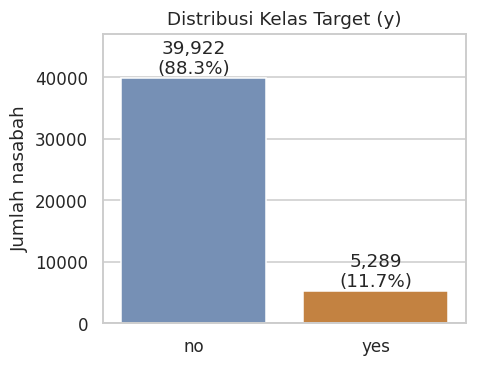

Rasio kelas mayoritas : minoritas = 7.5 : 1


In [8]:
# Distribusi kelas target
cnt = df['y'].value_counts()
pct = df['y'].value_counts(normalize=True) * 100
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.barplot(x=cnt.index, y=cnt.values, palette=['#6c8ebf', '#d9822b'], ax=ax)
for i, (c, p) in enumerate(zip(cnt.values, pct.values)):
    ax.text(i, c, f'{c:,}\n({p:.1f}%)', ha='center', va='bottom')
ax.set_title('Distribusi Kelas Target (y)'); ax.set_xlabel(''); ax.set_ylabel('Jumlah nasabah')
ax.set_ylim(0, cnt.max() * 1.18)
plt.tight_layout(); plt.show()
print(f'Rasio kelas mayoritas : minoritas = {cnt["no"]/cnt["yes"]:.1f} : 1')

Kelas **tidak seimbang**: sekitar 88% `no` dan 12% `yes`. Model yang selalu menebak `no` akan mencapai akurasi sekitar 88% tetapi tidak berguna, karena tidak menemukan satu pun calon pelanggan. Akurasi saja jadi metrik yang menyesatkan, sehingga evaluasi akan memakai **Precision, Recall, F1, ROC-AUC, dan PR-AUC**.

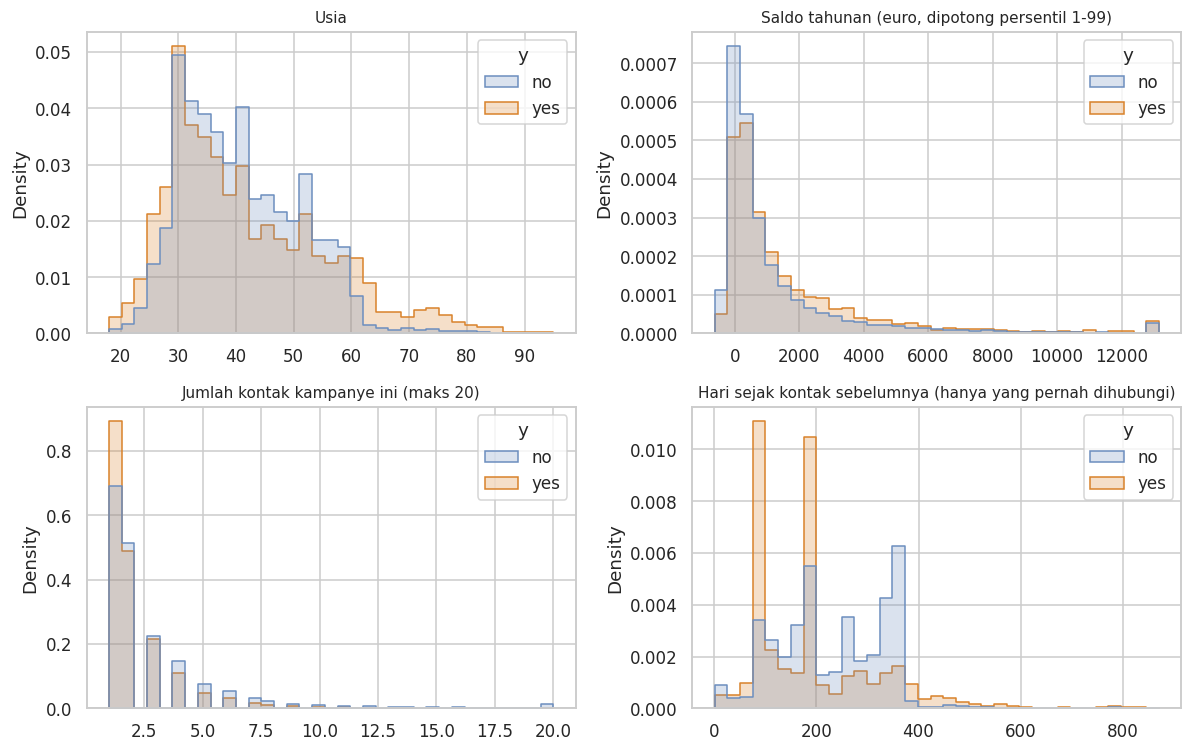

In [9]:
# Distribusi fitur numerik menurut kelas target
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
d = df.copy()
d['balance_clip'] = d['balance'].clip(d['balance'].quantile(.01), d['balance'].quantile(.99))
d['campaign_clip'] = d['campaign'].clip(upper=20)
d_prev = d[d['pdays'] > 0]
for ax, (col, data, title) in zip(axes.ravel(), [
        ('age', d, 'Usia'), ('balance_clip', d, 'Saldo tahunan (euro, dipotong persentil 1-99)'),
        ('campaign_clip', d, 'Jumlah kontak kampanye ini (maks 20)'),
        ('pdays', d_prev, 'Hari sejak kontak sebelumnya (hanya yang pernah dihubungi)')]):
    sns.histplot(data=data, x=col, hue='y', stat='density', common_norm=False,
                 element='step', bins=35, ax=ax, palette={'no': '#6c8ebf', 'yes': '#d9822b'})
    ax.set_title(title, fontsize=10); ax.set_xlabel('')
plt.tight_layout(); plt.show()

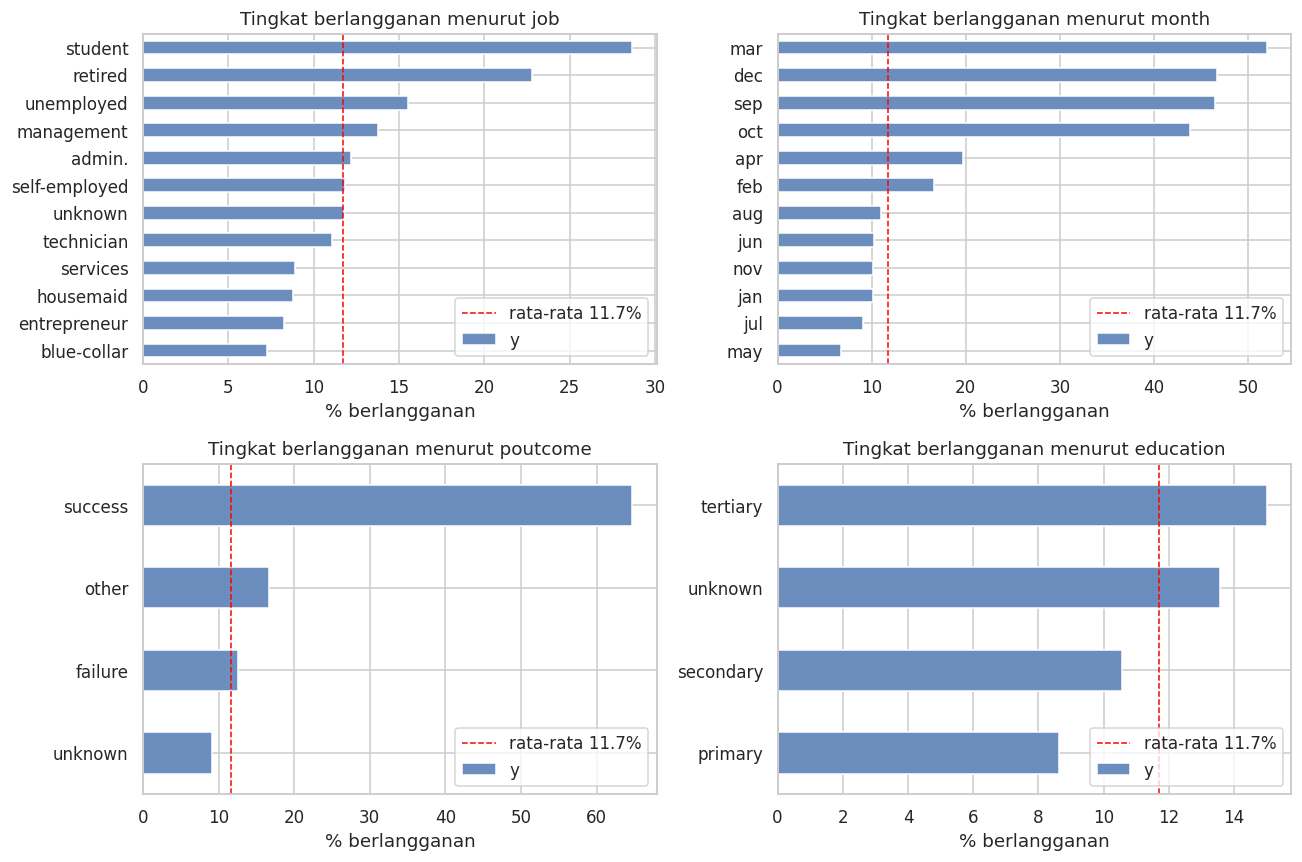

In [10]:
# Tingkat berlangganan (%) per kategori
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
base = (df['y'] == 'yes').mean() * 100
for ax, col in zip(axes.ravel(), ['job', 'month', 'poutcome', 'education']):
    rate = df.groupby(col)['y'].apply(lambda s: (s == 'yes').mean() * 100).sort_values()
    rate.plot.barh(ax=ax, color='#6c8ebf')
    ax.axvline(base, color='red', ls='--', lw=1, label=f'rata-rata {base:.1f}%')
    ax.set_title(f'Tingkat berlangganan menurut {col}'); ax.set_xlabel('% berlangganan'); ax.set_ylabel('')
    ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

**Temuan awal dari EDA:**
- **Riwayat kampanye:** nasabah dengan `poutcome = success` berlangganan lagi pada sekitar 65% kasus, jauh di atas rata-rata 11,7%.
- **Pekerjaan:** pelajar (`student`, 29%) dan pensiunan (`retired`, 23%) paling tinggi, sedangkan `blue-collar` paling rendah (7%).
- **Bulan kontak:** Maret, September, Oktober, dan Desember punya tingkat berlangganan 44–52%, tetapi volume panggilannya kecil. Mei menyumbang paling banyak panggilan (13.766) dengan tingkat berlangganan hanya ~7%. Banyak panggilan tidak menjamin hasil.
- **Jenis kontak:** nasabah dengan `contact = unknown` hanya ~4% yang berlangganan, dibanding ~15% untuk telepon seluler.

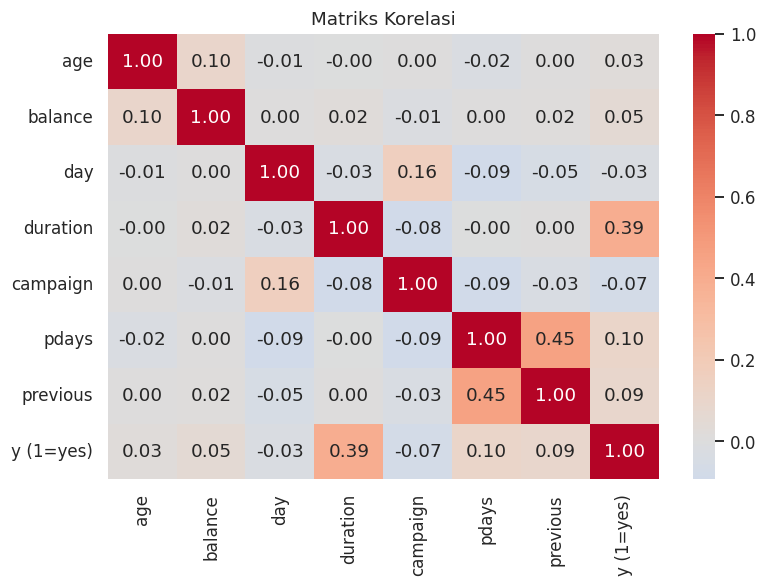

In [11]:
# Korelasi antar fitur numerik dan target
num_df = df.select_dtypes(include='number').copy()
num_df['y (1=yes)'] = (df['y'] == 'yes').astype(int)
plt.figure(figsize=(7.5, 5.5))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriks Korelasi'); plt.tight_layout(); plt.show()

Korelasi antar fitur numerik umumnya rendah, jadi tidak ada masalah multikolinearitas yang serius. `duration` punya korelasi terkuat dengan target, tetapi variabel ini tidak dipakai karena menyebabkan kebocoran data (lihat bagian 3).

### 4.4 Persiapan Data (Preprocessing)

Langkah yang dilakukan:
1. **Membuang `duration`** untuk mencegah kebocoran data.
2. **Menangani `pdays`.** Nilai `-1` artinya nasabah belum pernah dihubungi, tetapi angka `-1` menyesatkan bagi model. Dibuat fitur biner `pernah_dihubungi`, lalu `-1` diganti `0`.
3. **Nilai `unknown`** dipertahankan sebagai kategori sendiri.
4. **Encoding:** *One-Hot Encoding* untuk fitur kategorikal.
5. **Scaling:** `StandardScaler` untuk fitur numerik (penting bagi Logistic Regression).
6. **Pembagian data:** 80% latih dan 20% uji dengan *stratified split* agar proporsi kelas sama di kedua bagian.

Encoding dan scaling dimasukkan ke dalam `Pipeline`, sehingga statistik hanya dipelajari dari data latih. Ini mencegah kebocoran data saat validasi silang.

In [12]:
data = df.copy()
data['target'] = (data['y'] == 'yes').astype(int)
data['pernah_dihubungi'] = (data['pdays'] != -1).astype(int)
data['pdays'] = data['pdays'].replace(-1, 0)

X_full = data.drop(columns=['y', 'target'])          # masih memuat duration (untuk perbandingan di 5.8)
X = X_full.drop(columns=['duration'])                 # fitur untuk model utama
y = data['target']

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
print('Fitur numerik    :', num_cols)
print('Fitur kategorikal:', cat_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f'\nData latih: {X_train.shape}  | proporsi yes = {y_train.mean():.3%}')
print(f'Data uji  : {X_test.shape}  | proporsi yes = {y_test.mean():.3%}')

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
])

Fitur numerik    : ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'pernah_dihubungi']
Fitur kategorikal: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Data latih: (36168, 16)  | proporsi yes = 11.698%
Data uji  : (9043, 16)  | proporsi yes = 11.700%


### 4.5 Pemodelan

Empat model dilatih dalam `Pipeline` yang sama. Sebelum menyentuh data uji, perbandingan awal dilakukan dengan **validasi silang 5-fold (stratified)** pada data latih.

In [13]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced',
                                            n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE),
}
def make_pipe(model):
    return Pipeline([('prep', preprocess), ('model', model)])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, m in models.items():
    cv = cross_validate(make_pipe(m), X_train, y_train, cv=skf, n_jobs=-1,
                        scoring={'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'f1': 'f1'})
    rows.append({'Model': name,
                 'ROC-AUC (CV)': cv['test_roc_auc'].mean(), 'ROC-AUC std': cv['test_roc_auc'].std(),
                 'PR-AUC (CV)': cv['test_pr_auc'].mean(), 'F1 (CV)': cv['test_f1'].mean()})
cv_table = pd.DataFrame(rows).set_index('Model').round(4).sort_values('ROC-AUC (CV)', ascending=False)
cv_table

,ROC-AUC (CV),ROC-AUC std,PR-AUC (CV),F1 (CV)
Model,,,,
Gradient Boosting,0.7973,0.0017,0.4447,0.4495
Random Forest,0.7934,0.0036,0.4412,0.4733
Logistic Regression,0.7637,0.0032,0.3983,0.3732
Decision Tree,0.7483,0.0024,0.3474,0.4051


### 4.6 Evaluasi pada Data Uji (threshold default 0,5)

In [14]:
fitted, results = {}, []
for name, m in models.items():
    pipe = make_pipe(m).fit(X_train, y_train)
    fitted[name] = pipe
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    results.append({'Model': name,
                    'Accuracy': accuracy_score(y_test, pred),
                    'Precision': precision_score(y_test, pred),
                    'Recall': recall_score(y_test, pred),
                    'F1': f1_score(y_test, pred),
                    'ROC-AUC': roc_auc_score(y_test, proba),
                    'PR-AUC': average_precision_score(y_test, proba)})
res = pd.DataFrame(results).set_index('Model').round(4).sort_values('ROC-AUC', ascending=False)
res

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Gradient Boosting,0.8240,0.3584,0.6389,0.4592,0.8060,0.4626
Random Forest,0.8670,0.4438,0.5406,0.4874,0.8038,0.4518
Logistic Regression,0.7557,0.2671,0.6238,0.3740,0.7722,0.4095
Decision Tree,0.8232,0.3428,0.5577,0.4246,0.7566,0.3551


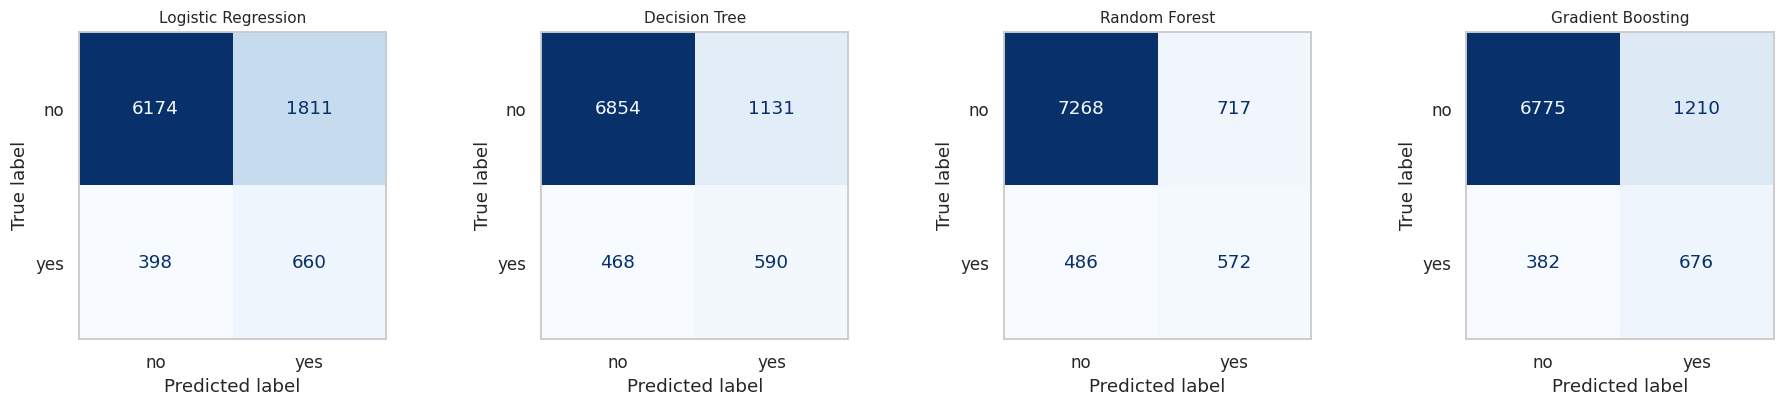

In [15]:
# Confusion matrix keempat model
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (name, pipe) in zip(axes, fitted.items()):
    pred = pipe.predict(X_test)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['no', 'yes']).plot(
        ax=ax, colorbar=False, cmap='Blues', values_format='d')
    ax.set_title(name, fontsize=10); ax.grid(False)
plt.tight_layout(); plt.show()

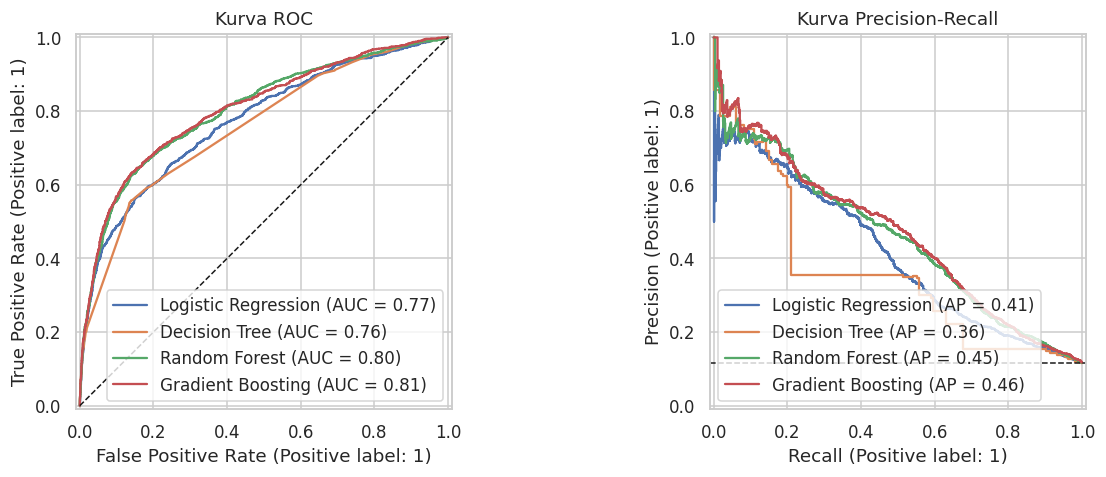

In [16]:
# Kurva ROC dan Precision-Recall
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_estimator(pipe, X_test, y_test, ax=axes[1], name=name)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1); axes[0].set_title('Kurva ROC')
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1); axes[1].set_title('Kurva Precision-Recall')
plt.tight_layout(); plt.show()

### 4.7 Tuning Hyperparameter Model Terbaik

In [17]:
best_name = res.index[0]
print('Model terbaik berdasarkan ROC-AUC data uji:', best_name)
print('(Peringkat CV:', ', '.join(cv_table.index), ')')

Model terbaik berdasarkan ROC-AUC data uji: Gradient Boosting
(Peringkat CV: Gradient Boosting, Random Forest, Logistic Regression, Decision Tree )


In [18]:
# Tuning Gradient Boosting dengan RandomizedSearchCV (3-fold, scoring ROC-AUC)
param_dist = {
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__max_iter': [100, 200, 300],
    'model__max_depth': [3, 5, None],
    'model__max_leaf_nodes': [15, 31, 63],
    'model__min_samples_leaf': [20, 50, 100],
    'model__l2_regularization': [0.0, 0.1, 1.0],
}
search = RandomizedSearchCV(
    make_pipe(HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
    param_dist, n_iter=15, cv=3, scoring='roc_auc', n_jobs=-1, random_state=RANDOM_STATE)
search.fit(X_train, y_train)
print('Parameter terbaik:', {k.replace('model__', ''): v for k, v in search.best_params_.items()})
print(f'ROC-AUC CV terbaik: {search.best_score_:.4f}')

tuned = search.best_estimator_
proba_tuned = tuned.predict_proba(X_test)[:, 1]
print(f'\nROC-AUC data uji  sebelum tuning: {res.loc["Gradient Boosting", "ROC-AUC"]:.4f}')
print(f'ROC-AUC data uji  sesudah tuning: {roc_auc_score(y_test, proba_tuned):.4f}')
print(f'PR-AUC  data uji  sesudah tuning: {average_precision_score(y_test, proba_tuned):.4f}')

Parameter terbaik: {'min_samples_leaf': 50, 'max_leaf_nodes': 31, 'max_iter': 200, 'max_depth': None, 'learning_rate': 0.05, 'l2_regularization': 0.0}
ROC-AUC CV terbaik: 0.7960

ROC-AUC data uji  sebelum tuning: 0.8060
ROC-AUC data uji  sesudah tuning: 0.8051
PR-AUC  data uji  sesudah tuning: 0.4662


**Memilih threshold keputusan.** Threshold 0,5 belum tentu optimal pada data tidak seimbang. Threshold dipilih dari prediksi **validasi silang pada data latih** (bukan data uji), sehingga data uji tetap murni untuk evaluasi akhir. Kriteria yang dipakai adalah F1-score maksimum.

Threshold optimal (F1 maks pada CV data latih): 0.621


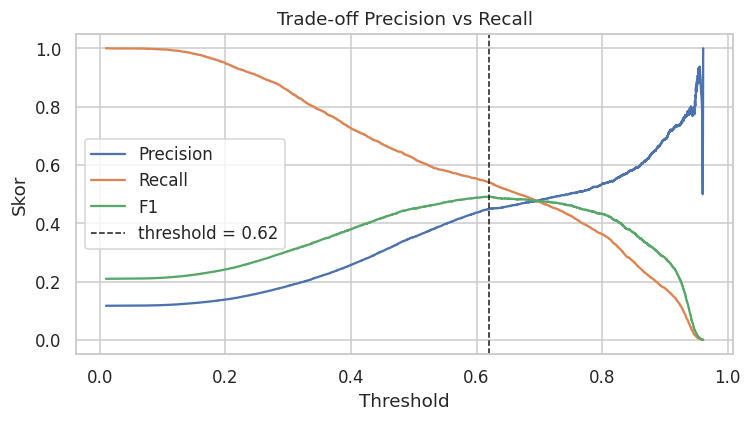

In [19]:
oof = cross_val_predict(tuned, X_train, y_train, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = float(thr[np.argmax(f1s)])
print(f'Threshold optimal (F1 maks pada CV data latih): {best_thr:.3f}')

plt.figure(figsize=(7, 4))
plt.plot(thr, prec[:-1], label='Precision'); plt.plot(thr, rec[:-1], label='Recall'); plt.plot(thr, f1s, label='F1')
plt.axvline(best_thr, color='k', ls='--', lw=1, label=f'threshold = {best_thr:.2f}')
plt.xlabel('Threshold'); plt.ylabel('Skor'); plt.title('Trade-off Precision vs Recall'); plt.legend()
plt.tight_layout(); plt.show()

,Accuracy,Precision,Recall,F1
Skenario,,,,
"Threshold default (0,5)",0.8205,0.3532,0.6427,0.4559
Threshold optimal (0.62),0.8707,0.4558,0.5406,0.4946


              precision    recall  f1-score   support

          no      0.938     0.914     0.926      7985
         yes      0.456     0.541     0.495      1058

    accuracy                          0.871      9043
   macro avg      0.697     0.728     0.710      9043
weighted avg      0.881     0.871     0.875      9043



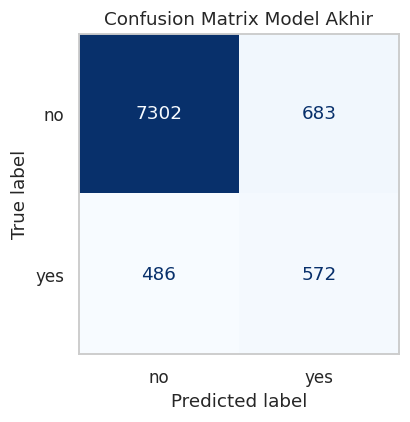

In [20]:
# Hasil akhir pada data uji
rows = []
for label, t in [('Threshold default (0,5)', 0.5), (f'Threshold optimal ({best_thr:.2f})', best_thr)]:
    pred = (proba_tuned >= t).astype(int)
    rows.append({'Skenario': label, 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred)})
final_tbl = pd.DataFrame(rows).set_index('Skenario').round(4)
display(final_tbl)

pred_final = (proba_tuned >= best_thr).astype(int)
print(classification_report(y_test, pred_final, target_names=['no', 'yes'], digits=3))
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_final), display_labels=['no', 'yes']).plot(
    ax=ax, colorbar=False, cmap='Blues', values_format='d')
ax.set_title('Confusion Matrix Model Akhir'); ax.grid(False); plt.tight_layout(); plt.show()

### 4.8 Faktor yang Paling Berpengaruh dan Uji Kebocoran `duration`

**Permutation importance** mengukur seberapa besar ROC-AUC turun ketika nilai satu fitur diacak. Semakin besar penurunannya, semakin penting fitur tersebut. Perhitungan memakai fitur asli sebelum *one-hot encoding*, sehingga hasilnya mudah dibaca.

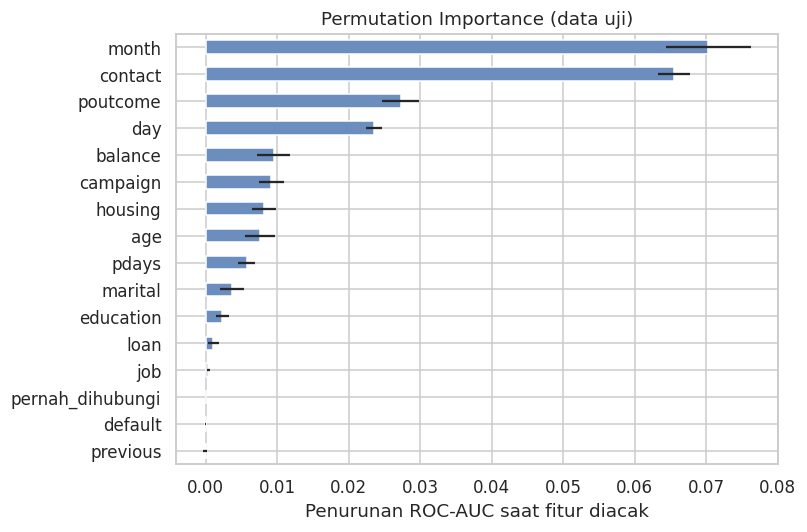

month       0.0703
contact     0.0655
poutcome    0.0273
day         0.0235
balance     0.0095
campaign    0.0092


In [21]:
pi = permutation_importance(tuned, X_test, y_test, scoring='roc_auc', n_repeats=5,
                            random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
plt.figure(figsize=(7.5, 5))
imp.plot.barh(xerr=pd.Series(pi.importances_std, index=X_test.columns)[imp.index], color='#6c8ebf')
plt.xlabel('Penurunan ROC-AUC saat fitur diacak'); plt.title('Permutation Importance (data uji)')
plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).head(6).round(4).to_string())

In [22]:
# Uji kebocoran: model yang sama dengan dan tanpa duration
Xtr_f, Xte_f = X_full.loc[X_train.index], X_full.loc[X_test.index]
num_f = Xtr_f.select_dtypes(include='number').columns.tolist()
prep_f = ColumnTransformer([('num', StandardScaler(), num_f),
                            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)])
with_dur = Pipeline([('prep', prep_f),
                     ('model', HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE))]
                    ).fit(Xtr_f, y_train)
auc_with = roc_auc_score(y_test, with_dur.predict_proba(Xte_f)[:, 1])
auc_without = roc_auc_score(y_test, fitted['Gradient Boosting'].predict_proba(X_test)[:, 1])
print(f'ROC-AUC TANPA duration (realistis) : {auc_without:.4f}')
print(f'ROC-AUC DENGAN duration (bocor)    : {auc_with:.4f}')
print(f'Selisih                            : +{auc_with - auc_without:.4f}')

ROC-AUC TANPA duration (realistis) : 0.8060
ROC-AUC DENGAN duration (bocor)    : 0.9329
Selisih                            : +0.1269


### 4.9 Manfaat Bisnis: Analisis Gains dan Lift

Bagian ini menjawab pertanyaan inti: *jika bank hanya menelepon nasabah dengan skor tertinggi, berapa banyak calon pelanggan yang tetap terjangkau?* Nasabah data uji diurutkan dari probabilitas tertinggi lalu dibagi menjadi 10 kelompok sama besar (desil).

,nasabah,berlangganan,response_rate_%,kumulatif_nasabah_%,kumulatif_terjangkau_%,lift
desil,,,,,,
1,905,478,52.8,10.0,45.2,4.51
2,904,190,21.0,20.0,63.1,1.79
3,904,94,10.4,30.0,72.0,0.89
4,905,72,8.0,40.0,78.8,0.68
5,904,47,5.2,50.0,83.3,0.44
6,904,45,5.0,60.0,87.5,0.43
7,905,42,4.6,70.0,91.5,0.39
8,904,46,5.1,80.0,95.8,0.44
9,904,20,2.2,90.0,97.7,0.19


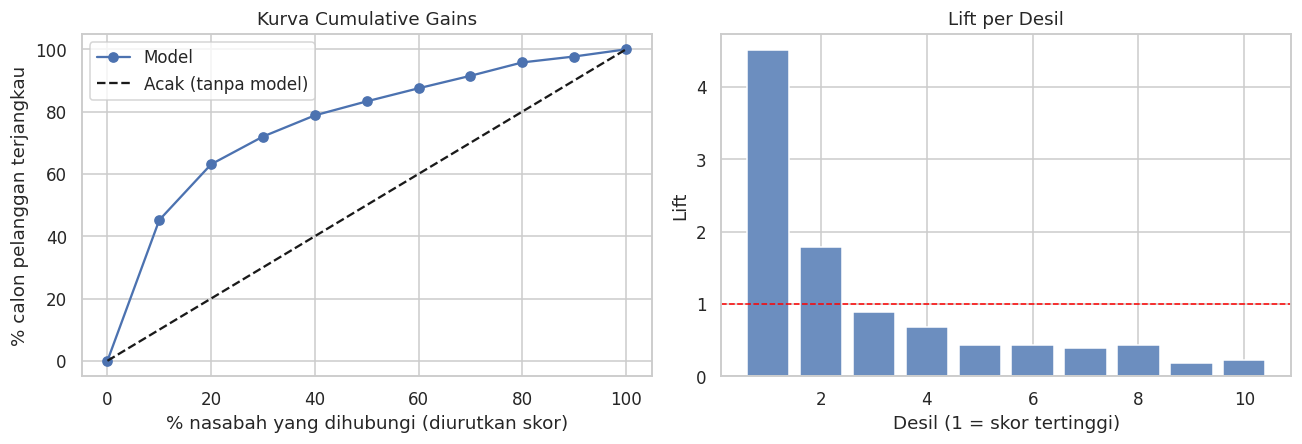

Menghubungi 10% nasabah teratas -> menjangkau 45.2% calon pelanggan (menghemat 90% panggilan)
Menghubungi 20% nasabah teratas -> menjangkau 63.1% calon pelanggan (menghemat 80% panggilan)
Menghubungi 30% nasabah teratas -> menjangkau 72.0% calon pelanggan (menghemat 70% panggilan)
Menghubungi 50% nasabah teratas -> menjangkau 83.3% calon pelanggan (menghemat 50% panggilan)


In [23]:
g = pd.DataFrame({'y': y_test.values, 'p': proba_tuned}).sort_values('p', ascending=False).reset_index(drop=True)
g['desil'] = g.index * 10 // len(g) + 1
gains = g.groupby('desil').agg(nasabah=('y', 'size'), berlangganan=('y', 'sum'))
gains['response_rate_%'] = (gains['berlangganan'] / gains['nasabah'] * 100).round(1)
gains['kumulatif_nasabah_%'] = (gains['nasabah'].cumsum() / gains['nasabah'].sum() * 100).round(0)
gains['kumulatif_terjangkau_%'] = (gains['berlangganan'].cumsum() / gains['berlangganan'].sum() * 100).round(1)
gains['lift'] = (gains['response_rate_%'] / (y_test.mean() * 100)).round(2)
display(gains)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.r_[0, gains['kumulatif_nasabah_%'].values]; yv = np.r_[0, gains['kumulatif_terjangkau_%'].values]
axes[0].plot(x, yv, marker='o', label='Model'); axes[0].plot([0, 100], [0, 100], 'k--', label='Acak (tanpa model)')
axes[0].set_xlabel('% nasabah yang dihubungi (diurutkan skor)'); axes[0].set_ylabel('% calon pelanggan terjangkau')
axes[0].set_title('Kurva Cumulative Gains'); axes[0].legend()
axes[1].bar(gains.index, gains['lift'], color='#6c8ebf'); axes[1].axhline(1, color='red', ls='--', lw=1)
axes[1].set_xlabel('Desil (1 = skor tertinggi)'); axes[1].set_ylabel('Lift'); axes[1].set_title('Lift per Desil')
plt.tight_layout(); plt.show()

for k in (1, 2, 3, 5):
    print(f'Menghubungi {k*10}% nasabah teratas -> menjangkau {gains.loc[k, "kumulatif_terjangkau_%"]:.1f}% calon pelanggan '
          f'(menghemat {100 - k*10}% panggilan)')

## 5. Hasil, Pembahasan, dan Manfaat

### 5.1 Ringkasan Hasil

| Aspek | Hasil |
|---|---|
| Model terbaik | **Gradient Boosting** (`HistGradientBoostingClassifier`) |
| ROC-AUC (data uji) | **≈ 0,806** (validasi silang 5-fold: 0,797) |
| PR-AUC (data uji) | **≈ 0,466** (pembanding acak: 0,117) |
| Threshold keputusan | 0,62 (dipilih dari validasi silang data latih) |
| Precision / Recall / F1 kelas `yes` | **0,456 / 0,541 / 0,495** |
| Accuracy | 0,871 |

**Perbandingan model.** Urutan ROC-AUC data uji adalah Gradient Boosting (0,806), Random Forest (0,804), Logistic Regression (0,772), dan Decision Tree (0,757). Dua metode berbasis ensemble unggul dari model tunggal, yang menunjukkan adanya pola non-linear dan interaksi antar fitur. Pada threshold 0,5, Random Forest punya precision dan F1 tertinggi, sedangkan Gradient Boosting punya recall tertinggi. Gradient Boosting dipilih karena ROC-AUC dan PR-AUC-nya paling tinggi dan kualitas pengurutannya tidak bergantung pada satu threshold.

**Tentang tuning.** Hasil `RandomizedSearchCV` hampir tidak mengubah performa (ROC-AUC data uji 0,8060 menjadi 0,8051), jadi pengaturan bawaan sudah mendekati optimal. Perbedaan sekecil itu masih dalam rentang fluktuasi acak dan tidak boleh disebut sebagai peningkatan.

**Tentang akurasi.** Akurasi model akhir (87,1%) sedikit di bawah model yang selalu menebak `no` (sekitar 88,3%). Itu wajar dan bukan kegagalan. Model "selalu tidak" tidak menemukan satu pun calon pelanggan, sedangkan model ini menemukan sekitar 54% dari seluruh calon pelanggan di data uji dengan ketepatan 45,6%, kira-kira empat kali lipat dari peluang acak (11,7%). Karena itu metrik utama yang dipakai adalah ROC-AUC, PR-AUC, Precision, Recall, dan F1.

### 5.2 Faktor yang Paling Berpengaruh

Berdasarkan *permutation importance*, fitur terpenting adalah **`month`** (0,070), **`contact`** (0,066), **`poutcome`** (0,027), dan **`day`** (0,024). Fitur profil nasabah seperti `balance` dan `campaign` jauh lebih kecil pengaruhnya (sekitar 0,01).

Artinya, **kapan dan bagaimana nasabah dihubungi** serta **hasil kampanye sebelumnya** lebih menentukan daripada profil demografisnya. Hal ini sejalan dengan EDA: nasabah yang pernah berhasil (`success`) sangat mungkin berlangganan lagi, dan kontak dengan jenis `unknown` jarang berhasil.

### 5.3 Temuan Kebocoran Data (`duration`)

Dengan model dan data yang sama, menambahkan `duration` menaikkan ROC-AUC dari **0,806 menjadi 0,933** (selisih +0,127). Lonjakan ini semu karena lama telepon baru diketahui setelah panggilan selesai. Model dengan `duration` tidak bisa dipakai untuk memutuskan siapa yang perlu ditelepon, sehingga model utama tanpa `duration` adalah yang realistis untuk dipakai.

### 5.4 Manfaat Bisnis

Pada data uji (9.043 nasabah, dengan 1.058 calon pelanggan sebenarnya), nasabah diurutkan menurut skor model:

| Jika bank hanya menelepon… | Calon pelanggan yang terjangkau | Panggilan yang dihemat |
|---|---|---|
| 10% nasabah teratas | **45,2%** | 90% |
| 20% nasabah teratas | **63,1%** | 80% |
| 30% nasabah teratas | **72,0%** | 70% |
| 50% nasabah teratas | **83,3%** | 50% |

Desil teratas punya tingkat respons 52,8%, atau **lift 4,5×** dibanding menelepon acak (11,7%). Manfaat praktisnya:
1. **Efisiensi biaya:** bank bisa menjangkau sekitar tiga perempat calon pelanggan hanya dengan menelepon 30% nasabah.
2. **Prioritas kerja tim pemasaran:** daftar nasabah diurutkan menurut skor, sehingga petugas menelepon yang paling menjanjikan lebih dulu.
3. **Kenyamanan nasabah:** nasabah dengan peluang kecil tidak terlalu sering diganggu.
4. **Dasar kebijakan:** temuan tentang bulan, jenis kontak, dan riwayat kampanye bisa dipakai untuk merencanakan waktu dan saluran kampanye berikutnya.

### 5.5 Keterbatasan dan Saran Pengembangan

- **Pembagian data acak.** Data berurutan waktu (2008–2010), sedangkan pembagian latih/uji dilakukan acak. Fitur seperti `month` dan `day` bisa menangkap pola khusus periode kampanye. Untuk penerapan nyata, validasi sebaiknya memakai pembagian **berdasarkan waktu** (latih pada data lama, uji pada data terbaru). Angka di atas mungkin sedikit lebih optimis daripada kinerja sebenarnya.
- **Analisis biaya-manfaat** belum dilakukan. Threshold ideal bergantung pada biaya satu panggilan dan keuntungan satu deposito, yang tidak tersedia di dataset.
- **Data satu bank, satu periode.** Model perlu dilatih ulang dan diuji ulang sebelum dipakai di konteks lain.
- **Saran lanjutan:** mencoba `bank-additional-full.csv` (memuat variabel ekonomi makro), teknik penanganan ketidakseimbangan kelas seperti SMOTE, serta kalibrasi probabilitas.
- **Aspek etika:** pemakaian fitur seperti usia dan status pernikahan untuk memprioritaskan nasabah perlu dipertimbangkan dari sisi keadilan (*fairness*).

### 5.6 Kesimpulan

Masalah klasifikasi "apakah nasabah akan berlangganan deposito berjangka" dapat diselesaikan dengan *machine learning* secara bermanfaat, meskipun data sangat tidak seimbang. **Gradient Boosting** memberi hasil terbaik (ROC-AUC ≈ 0,81, F1 ≈ 0,49 pada kelas `yes`). Model ini menjangkau sekitar 72% calon pelanggan hanya dengan menelepon 30% nasabah teratas. Tiga pelajaran penting dari studi kasus ini: (1) akurasi menyesatkan pada data tidak seimbang, (2) variabel `duration` harus dibuang karena menyebabkan kebocoran data, dan (3) waktu serta saluran kontak dan riwayat kampanye lebih menentukan keberhasilan daripada profil nasabah.

## 6. Referensi

1. Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems*, 62, 22–31. https://doi.org/10.1016/j.dss.2014.03.001
2. Moro, S., Laureano, R., & Cortez, P. (2011). Using data mining for bank direct marketing: An application of the CRISP-DM methodology. *Proceedings of the European Simulation and Modelling Conference (ESM'2011)*, 117–121. EUROSIS. http://hdl.handle.net/1822/14838
3. Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306 (https://archive.ics.uci.edu/dataset/222/bank+marketing)
4. Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
5. Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
6. Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics*, 29(5), 1189–1232.
7. Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3), e0118432.
8. Han, J., Kamber, M., & Pei, J. (2012). *Data Mining: Concepts and Techniques* (3rd ed.). Morgan Kaufmann.
9. Wirth, R., & Hipp, J. (2000). CRISP-DM: Towards a standard process model for data mining. *Proceedings of the 4th International Conference on the Practical Applications of Knowledge Discovery and Data Mining*, 29–39.